In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures 
from sklearn.linear_model import LinearRegression 
  
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score,mean_absolute_percentage_error, explained_variance_score,max_error ) 


In [3]:
data = 'Fish.csv'
df = pd.read_csv(data) 

In [4]:
df.head()

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


In [8]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Weight             159 non-null    float64
 1   Length1            159 non-null    float64
 2   Length2            159 non-null    float64
 3   Length3            159 non-null    float64
 4   Height             159 non-null    float64
 5   Width              159 non-null    float64
 6   Species_Parkki     159 non-null    bool   
 7   Species_Perch      159 non-null    bool   
 8   Species_Pike       159 non-null    bool   
 9   Species_Roach      159 non-null    bool   
 10  Species_Smelt      159 non-null    bool   
 11  Species_Whitefish  159 non-null    bool   
dtypes: bool(6), float64(6)
memory usage: 8.5 KB


In [9]:
df.shape

(159, 12)

In [12]:
X = df.drop("Weight", axis=1) 
y = df["Weight"] 
  

In [13]:
x1, x2, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
  


In [14]:
poly = PolynomialFeatures(degree=2) 

In [15]:
X_train_poly = poly.fit_transform(x1) 
X_test_poly = poly.transform(x2) 


In [16]:
model =LinearRegression()

In [17]:
model.fit(X_train_poly, y_train) 

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](78,)","[ 0. , 149.74,-516.58,..., 19.9 , 0. , -75.12]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.243
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,78
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(52)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](78,)","[19617.52, 2519.01, 758.56,..., 0. , 0. , 0. ]"


In [19]:
y_pred = model.predict(X_test_poly) 
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse) 
r2 = r2_score(y_test, y_pred) 
mape = mean_absolute_percentage_error(y_test, y_pred)
evs = explained_variance_score(y_test, y_pred) 
maxerr = max_error(y_test, y_pred) 


In [22]:
n=X_test_poly.shape[0] 
p= X_test_poly.shape[1] - 1 
  
adj_r2 = 1 - ((1-r2)*(n-1)/(n-p-1)) 


In [23]:
print("\n========== Evaluation Metrics ==========") 
  
print("MAE :", mae) 
print("MSE :", mse)
print("RMSE :", rmse)
print("R2 Score :", r2) 
print("Adjusted R2 :", adj_r2) 
print("MAPE :", mape) 
print("Explained Variance :", evs)
print("Maximum Error :", maxerr) 



========== Evaluation Metrics ==========
MAE : 48.40982364398457
MSE : 5620.712917626417
RMSE : 74.97141400311466
R2 Score : 0.9604841036350984
Adjusted R2 : 1.0266302779850425
MAPE : 0.24553055496987397
Explained Variance : 0.9618750799875123
Maximum Error : 266.19008812688685


In [32]:
X = df[['Length3']] 

y = df['Weight'] 
poly = PolynomialFeatures(degree=2) 
  
X_poly = poly.fit_transform(X) 
  
model = LinearRegression()
model.fit(X_poly, y)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0. ,8.8 ,0.29]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-202.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[10042.01, 33.7 , 0. ]"


In [33]:
X_grid = np.arange( 
    X.min().values[0], 
    X.max().values[0], 
    0.1 
).reshape(-1,1) 

C:\Users\acer\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


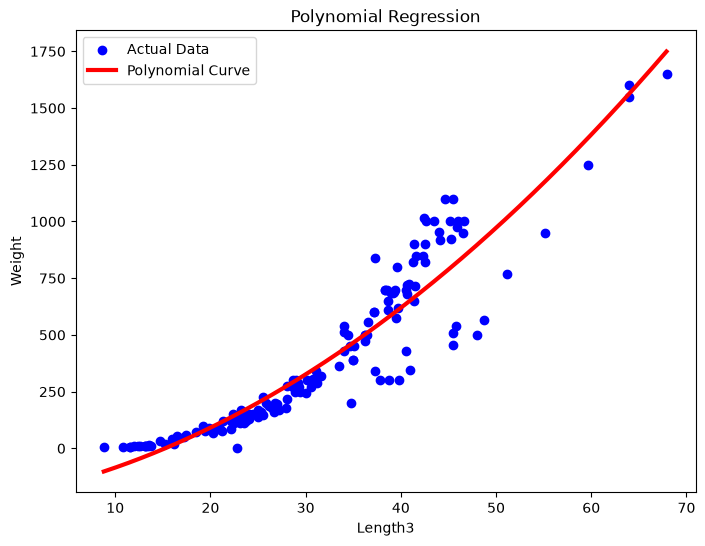

In [34]:
plt.figure(figsize=(8,6)) 
  
plt.scatter(X, y, color="blue", label="Actual Data") 
  
plt.plot(     X_grid,     model.predict(poly.transform(X_grid)),     color="red",     linewidth=3, 
    label="Polynomial Curve" 
) 
  
plt.xlabel("Length3") 
plt.ylabel("Weight") 
plt.title("Polynomial Regression") 
plt.legend() 
plt.show() 
